In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, gc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
import xgboost as xgb
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)

df = pd.read_parquet('../data/processed/02_features.parquet')
print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} cols")
print(f"Fraud rate: {df['isFraud'].mean():.4%}")

Loaded: 590,540 rows × 77 cols
Fraud rate: 3.4990%


In [6]:
DROP_COLS = ['TransactionID', 'isFraud', 'TransactionDT']

X = df.drop(columns=DROP_COLS)
y = df['isFraud']

for col in X.select_dtypes(exclude=['number']).columns:
    X[col] = pd.Categorical(X[col]).codes.astype('int16')

remaining = X.select_dtypes(exclude=['number']).columns.tolist()
print(f"Non-numeric columns remaining: {remaining}")  # should be []

X = X.fillna(X.median(numeric_only=True))

print(f"Feature matrix : {X.shape}")
print(f"Any NaNs left  : {X.isnull().any().any()}")
print(f"Dtypes sample  :\n{X.dtypes.value_counts()}")

Non-numeric columns remaining: []
Feature matrix : (590540, 74)
Any NaNs left  : False
Dtypes sample  :
float64    22
int8       17
int16      16
float32    14
int32       5
Name: count, dtype: int64


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        
    random_state=42,      
    stratify=y            
)

print(f"Train size : {X_train.shape[0]:,} rows")
print(f"Test size  : {X_test.shape[0]:,} rows")
print(f"Train fraud: {y_train.mean():.4%}")
print(f"Test fraud : {y_test.mean():.4%}")


Train size : 472,432 rows
Test size  : 118,108 rows
Train fraud: 3.4989%
Test fraud : 3.4993%


In [8]:

def evaluate_model(name, model, X_test, y_test, threshold=0.5):
    """
    Comprehensive evaluation for fraud detection models.
    Uses probability scores, not just binary predictions.
    """
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    roc_auc  = roc_auc_score(y_test, y_prob)
    avg_prec = average_precision_score(y_test, y_prob)
    
    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(f"  ROC-AUC  : {roc_auc:.4f}   (1.0 = perfect, 0.5 = random)")
    print(f"  PR-AUC   : {avg_prec:.4f}  (primary metric for fraud)")
    print(f"\n{classification_report(y_test, y_pred, target_names=['Legit','Fraud'])}")

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    print(f"  True Negatives  (correct legit) : {tn:,}")
    print(f"  False Positives (legit→fraud)   : {fp:,}  ← Hawk's key metric")
    print(f"  False Negatives (fraud missed)  : {fn:,}")
    print(f"  True Positives  (caught fraud)  : {tp:,}")
    print(f"\n  False Positive Rate: {fp/(fp+tn):.4%}")
    print(f"  Fraud Recall (catch rate): {tp/(tp+fn):.4%}")

    return y_prob, roc_auc, avg_prec


def plot_curves(results, y_test):
    """
    Plot ROC and Precision-Recall curves for all models side by side.
    PR curve is more informative than ROC for imbalanced data.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    for name, y_prob in results.items():
        # ROC curve
        RocCurveDisplay.from_predictions(
            y_test, y_prob, name=name, ax=axes[0]
        )
        # PR curve
        PrecisionRecallDisplay.from_predictions(
            y_test, y_prob, name=name, ax=axes[1]
        )

    axes[0].set_title('ROC Curve — all models', fontsize=13, fontweight='bold')
    axes[0].plot([0,1],[0,1],'k--', alpha=0.4, label='Random')

    axes[1].set_title('Precision-Recall Curve — all models',
                      fontsize=13, fontweight='bold')
    axes[1].axhline(y=y_test.mean(), color='k', linestyle='--',
                    alpha=0.4, label=f'Baseline ({y_test.mean():.3f})')

    for ax in axes:
        ax.legend(loc='lower left' if ax == axes[0] else 'upper right')
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('../reports/model_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

In [9]:

scaler   = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Training Logistic Regression...")
lr = LogisticRegression(
    class_weight='balanced',  
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)
lr.fit(X_train_scaled, y_train)

prob_lr, roc_lr, pr_lr = evaluate_model(
    "Logistic Regression", lr, X_test_scaled, y_test
)
print("\nLogistic Regression done.")

Training Logistic Regression...

  Logistic Regression
  ROC-AUC  : 0.8295   (1.0 = perfect, 0.5 = random)
  PR-AUC   : 0.2142  (primary metric for fraud)

              precision    recall  f1-score   support

       Legit       0.99      0.75      0.85    113975
       Fraud       0.10      0.76      0.18      4133

    accuracy                           0.75    118108
   macro avg       0.54      0.75      0.52    118108
weighted avg       0.96      0.75      0.83    118108

  True Negatives  (correct legit) : 85,818
  False Positives (legit→fraud)   : 28,157  ← Hawk's key metric
  False Negatives (fraud missed)  : 1,008
  True Positives  (caught fraud)  : 3,125

  False Positive Rate: 24.7045%
  Fraud Recall (catch rate): 75.6109%

Logistic Regression done.


In [10]:
print("Training Random Forest (this takes 3–5 mins)...")
rf = RandomForestClassifier(
    n_estimators=100,         
    max_depth=12,             
    min_samples_leaf=20,      
    class_weight='balanced',  
    random_state=42,
    n_jobs=-1                 
)
rf.fit(X_train, y_train)

prob_rf, roc_rf, pr_rf = evaluate_model(
    "Random Forest", rf, X_test, y_test
)

Training Random Forest (this takes 3–5 mins)...

  Random Forest
  ROC-AUC  : 0.9203   (1.0 = perfect, 0.5 = random)
  PR-AUC   : 0.5971  (primary metric for fraud)

              precision    recall  f1-score   support

       Legit       0.99      0.91      0.95    113975
       Fraud       0.24      0.76      0.37      4133

    accuracy                           0.91    118108
   macro avg       0.62      0.84      0.66    118108
weighted avg       0.96      0.91      0.93    118108

  True Negatives  (correct legit) : 104,148
  False Positives (legit→fraud)   : 9,827  ← Hawk's key metric
  False Negatives (fraud missed)  : 978
  True Positives  (caught fraud)  : 3,155

  False Positive Rate: 8.6221%
  Fraud Recall (catch rate): 76.3368%


In [11]:

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos = neg_count / pos_count
print(f"scale_pos_weight = {scale_pos:.1f}  "
      f"(fraud is {scale_pos:.0f}x rarer than legit)")

print("\nTraining XGBoost...")
xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,            
    colsample_bytree=0.8,     
    scale_pos_weight=scale_pos, 
    eval_metric='aucpr',      
    random_state=42,
    n_jobs=-1,
    verbosity=0
)
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],   
    verbose=50                     
)

prob_xgb, roc_xgb, pr_xgb = evaluate_model(
    "XGBoost", xgb_model, X_test, y_test
)

scale_pos_weight = 27.6  (fraud is 28x rarer than legit)

Training XGBoost...
[0]	validation_0-aucpr:0.34159
[50]	validation_0-aucpr:0.51318
[100]	validation_0-aucpr:0.55668
[150]	validation_0-aucpr:0.58097
[200]	validation_0-aucpr:0.59903
[250]	validation_0-aucpr:0.61380
[299]	validation_0-aucpr:0.62907

  XGBoost
  ROC-AUC  : 0.9380   (1.0 = perfect, 0.5 = random)
  PR-AUC   : 0.6291  (primary metric for fraud)

              precision    recall  f1-score   support

       Legit       0.99      0.90      0.95    113975
       Fraud       0.23      0.82      0.36      4133

    accuracy                           0.90    118108
   macro avg       0.61      0.86      0.65    118108
weighted avg       0.97      0.90      0.93    118108

  True Negatives  (correct legit) : 102,846
  False Positives (legit→fraud)   : 11,129  ← Hawk's key metric
  False Negatives (fraud missed)  : 734
  True Positives  (caught fraud)  : 3,399

  False Positive Rate: 9.7644%
  Fraud Recall (catch rate): 82.2

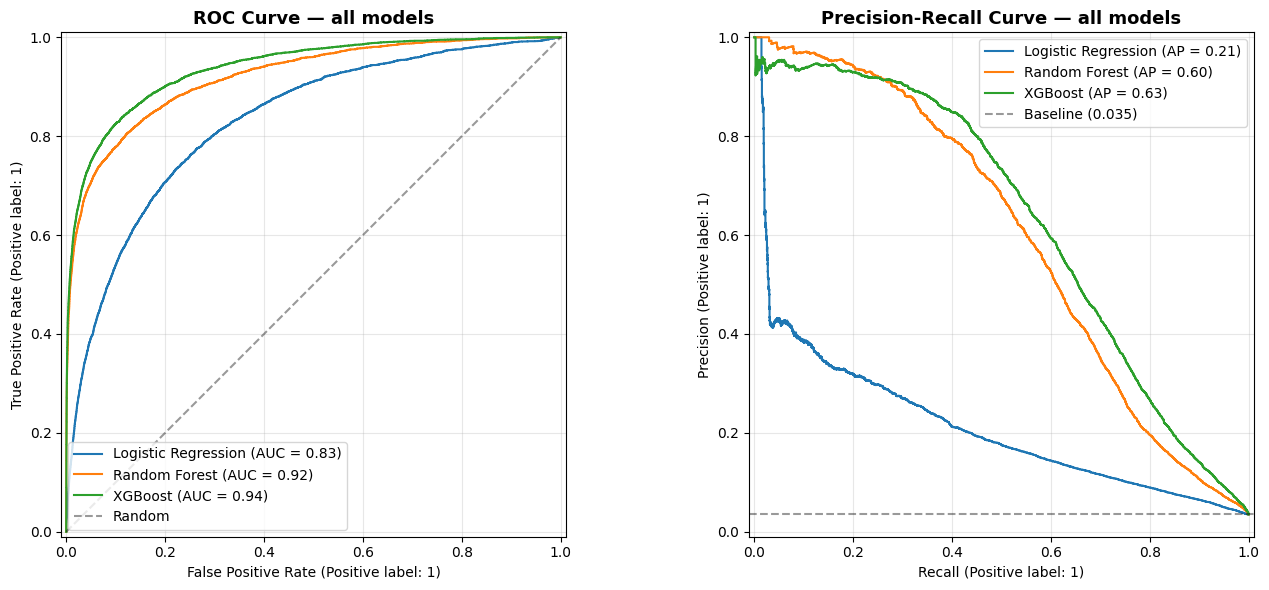


── Model Comparison ──────────────────────────
              Model  ROC-AUC   PR-AUC
            XGBoost 0.938027 0.629122
      Random Forest 0.920275 0.597061
Logistic Regression 0.829544 0.214180

Best model by PR-AUC (primary metric): XGBoost


In [12]:

results = {
    "Logistic Regression": prob_lr,
    "Random Forest":       prob_rf,
    "XGBoost":             prob_xgb,
}
plot_curves(results, y_test)

summary = pd.DataFrame({
    'Model':   ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'ROC-AUC': [roc_lr, roc_rf, roc_xgb],
    'PR-AUC':  [pr_lr,  pr_rf,  pr_xgb],
}).sort_values('PR-AUC', ascending=False)

print("\n── Model Comparison ──────────────────────────")
print(summary.to_string(index=False))
print("\nBest model by PR-AUC (primary metric):",
      summary.iloc[0]['Model'])

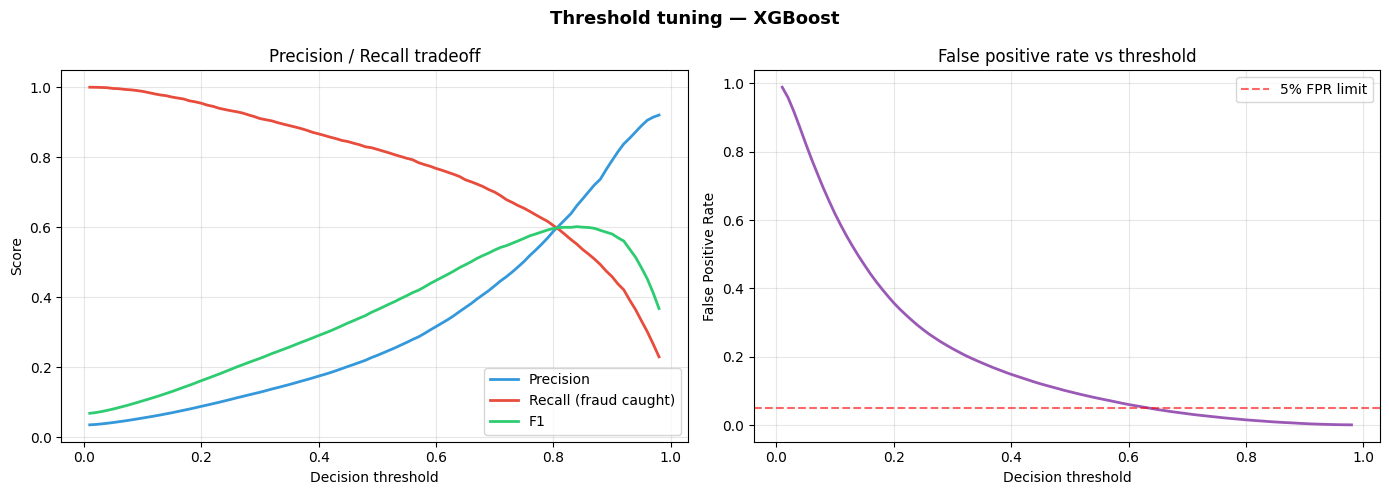


── Optimal threshold for XGBoost ──
   Target: catch ≥75% of fraud
   Threshold : 0.63
   Fraud caught   : 75.13%
   False pos rate : 5.13%
   Precision      : 34.68%


In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

def tune_threshold(name, y_prob, y_test):
    """
    Find the optimal decision threshold by sweeping from 0.01 to 0.99.
    In fraud detection, you tune threshold to meet a business constraint:
    e.g. 'catch at least 80% of fraud while keeping FPR below 5%'
    """
    thresholds = np.arange(0.01, 0.99, 0.01)
    results = []

    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
        results.append({
            'threshold': t,
            'precision': precision_score(y_test, y_pred, zero_division=0),
            'recall':    recall_score(y_test, y_pred, zero_division=0),
            'f1':        f1_score(y_test, y_pred, zero_division=0),
            'fpr':       fp / (fp + tn),  
            'fraud_caught': tp / (tp + fn) 
        })

    df_thresh = pd.DataFrame(results)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Threshold tuning — {name}', fontsize=13, fontweight='bold')

    axes[0].plot(df_thresh['threshold'], df_thresh['precision'],
                 label='Precision', color='#3498db', linewidth=2)
    axes[0].plot(df_thresh['threshold'], df_thresh['recall'],
                 label='Recall (fraud caught)', color='#e74c3c', linewidth=2)
    axes[0].plot(df_thresh['threshold'], df_thresh['f1'],
                 label='F1', color='#2ecc71', linewidth=2)
    axes[0].set_xlabel('Decision threshold')
    axes[0].set_ylabel('Score')
    axes[0].set_title('Precision / Recall tradeoff')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(df_thresh['threshold'], df_thresh['fpr'],
                 color='#9b59b6', linewidth=2)
    axes[1].axhline(0.05, color='red', linestyle='--',
                    alpha=0.6, label='5% FPR limit')
    axes[1].set_xlabel('Decision threshold')
    axes[1].set_ylabel('False Positive Rate')
    axes[1].set_title('False positive rate vs threshold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'../reports/threshold_tuning_{name.replace(" ","_")}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

    target_recall = 0.75
    candidates = df_thresh[df_thresh['recall'] >= target_recall]
    if len(candidates) > 0:
        best = candidates.loc[candidates['fpr'].idxmin()]
        print(f"\n── Optimal threshold for {name} ──")
        print(f"   Target: catch ≥{target_recall:.0%} of fraud")
        print(f"   Threshold : {best['threshold']:.2f}")
        print(f"   Fraud caught   : {best['recall']:.2%}")
        print(f"   False pos rate : {best['fpr']:.2%}")
        print(f"   Precision      : {best['precision']:.2%}")
    
    return df_thresh

thresh_xgb = tune_threshold("XGBoost", prob_xgb, y_test)

In [14]:
import joblib

joblib.dump(lr,        '../models/logistic_regression.pkl')
joblib.dump(scaler,    '../models/scaler.pkl')
joblib.dump(rf,        '../models/random_forest.pkl')
joblib.dump(xgb_model, '../models/xgboost.pkl')

pd.DataFrame({
    'y_true':   y_test.values,
    'prob_lr':  prob_lr,
    'prob_rf':  prob_rf,
    'prob_xgb': prob_xgb
}, index=y_test.index).to_parquet('../data/processed/03_predictions.parquet')

print("✓ Models saved to models/")
print("✓ Predictions saved to data/processed/03_predictions.parquet")
#print("\nPhase 3 complete. XGBoost is your best baseline.")
#print("Phase 4: LightGBM + SHAP explainability — the Hawk differentiator.")

✓ Models saved to models/
✓ Predictions saved to data/processed/03_predictions.parquet
